# EDA - Exploratory Data Analysis
> This notebook was refactored to run core EDA steps on the full dataset to ensure that reported distributions, correlations and imbalance characteristics reflect real data behavior.
> Earlier stratified and balanced subsets were retained only where methodologically appropriate for exploratory or class-conditional analysis.

## Load the datasets

In [17]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_context("notebook")

In [18]:
creditcard = pd.read_csv("../data/raw/creditcard.csv")
paysim = pd.read_csv("../data/raw/paysim.csv")

In [19]:
creditcard.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [20]:
paysim.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [21]:
creditcard.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

The creditcard dataset contains 284807 rows and 31 columns. All features are stored as floating-point values. `Class` column which is the target, is integer.  

In the `Class` column, 1 indicates fraudulent transactions and 0 indicates normal ones. This dataset is suitable for both supervised fraud classification and unsupervised anomaly detection due to its extreme class imbalance.

As mentioned in the official dataset description in Kaggle, most features (`V1` - `V28`) are PCA-transformed and anonymized due to confidentiality concerns, meaning their original semantic meaning is unknown. This limits interpretability but simplifies preprocessing and reduces the need for extensive scaling compared to raw transactional data.

In [22]:
paysim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


The paysim dataset contains 6362620 rows and 11 columns. Most features are floating points. There's also categorical columns including `type`, `nameOrig`, and `nameDest` columns. There are also three integer columns: `step`, `isFraud`, and `isFlaggedFraud`.

The primary target variable is `isFraud`. The `isFlaggedFraud` column represents rule-based detection and should not be used as a predictive feature to avoid leakage.

Columns related to account balances (`oldbalance*`, `newbalance*`) should be used with caution. In some fraud cases, transactions are canceled, which can lead to inconsistent or misleading balance values. These features may introduce partial leakage or distort model learning if not handled carefully.

### Implications for preprocessing
- Numerical features require scaling due to different ranges, especially in the PaySim dataset.
- Categorical features in PaySim require encoding.
- Columns that introduce leakage must be excluded.
- Severe class imbalance must be handled carefully during evaluation.

## Class Imbalance Analysis

### creditcard dataset

In [24]:
# class frequency in target variable
class_count = creditcard['Class'].value_counts()
class_count

,count
Class,
0,284315
1,492


In [25]:
# percentage of each class in target variable
creditcard['Class'].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


In [26]:
# create dataframe for plotting
class_count_df = class_count.reset_index()
# rename columns
class_count_df.columns = ['Class', 'Count']
class_count_df

,Class,Count
0,0,284315
1,1,492


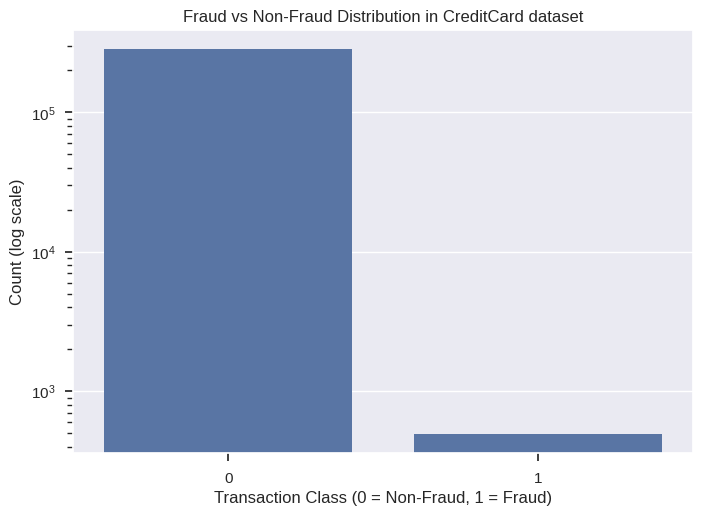

In [27]:
# plotting class distribution
sns.barplot(
    x='Class',
    y='Count',
    data=class_count_df
)

plt.yscale('log')
plt.title('Fraud vs Non-Fraud Distribution in CreditCard dataset')
plt.xlabel("Transaction Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Count (log scale)")

plt.show()

#### Interpretation
We can clearly observe the imbalance in the dataset. Only **~0.17** percent of transactions are fraudulent. So it is necessary to be cautious about the metrics we use to evaluate our model. For instance, high accuracy could be obviously very misleading as the model can falsely learn to just predict non-fraud for each transaction and get a high accuracy.

This highlights the need for alternative evaluation metrics such as precision, recall, and F1-score in later stages.

### paysim dataset

In [28]:
# class frequency in target variable
class_count = paysim['isFraud'].value_counts()
class_count

,count
isFraud,
0,6354407
1,8213


In [29]:
# percentage of each class in target variable
paysim['isFraud'].value_counts(normalize=True) * 100

,proportion
isFraud,
0,99.870918
1,0.129082


In [30]:
# create dataframe for plotting
class_count_df = class_count.reset_index()
# rename columns
class_count_df.columns = ['Class', 'Count']
class_count_df

,Class,Count
0,0,6354407
1,1,8213


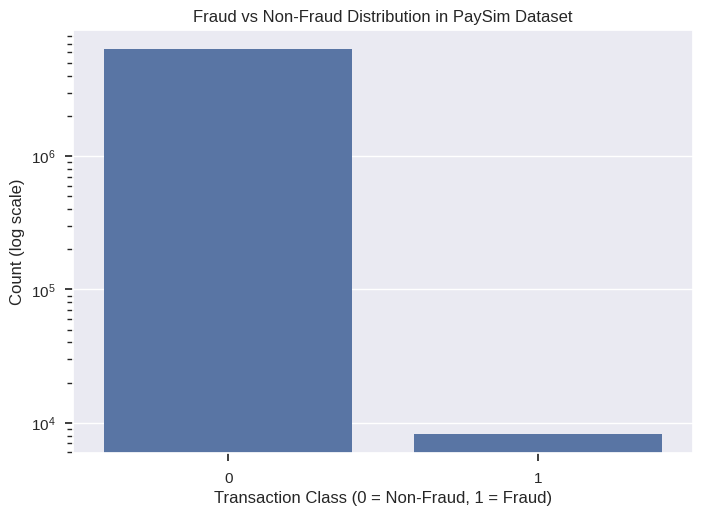

In [31]:
# plotting class distribution
sns.barplot(
    x='Class',
    y='Count',
    data=class_count_df
)

plt.yscale('log')
plt.title('Fraud vs Non-Fraud Distribution in PaySim Dataset')
plt.xlabel("Transaction Class (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Count (log scale)")

plt.show()

#### Interpretation
Compared to the CreditCard dataset, PaySim shows an even rarer fraud class, making fraud detection more challenging and reinforcing the need for careful handling of imbalance.

## Missing Values & Duplicates

In [32]:
creditcard.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [33]:
paysim.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


No explicit missing values were found in any columns of the datasets.

In [34]:
creditcard.duplicated().sum()

np.int64(1081)

In [37]:
creditcard = creditcard.drop_duplicates()

The Credit Card dataset contains 1,081 fully duplicated records (~0.38% of the data). As these rows are exact duplicates across all features and the class label, they are likely artifacts of data collection rather than independent transactions. To avoid unintended weighting effects in downstream analysis, these duplicates were removed.

In [35]:
paysim.duplicated().sum()

np.int64(0)

No duplicate rows were found in the paysim datasets.

## Feature Distribution Analysis

### CreditCard Dataset

In [39]:
# select numerical columns
target_col = 'Class'
num_cols = creditcard.select_dtypes(include=['int64','float64']).drop(columns=[target_col])

print(f"number of numerical columns: {len(num_cols.columns)}")

number of numerical columns: 30


#### Interpretable Features: 'Amount' & 'Time'

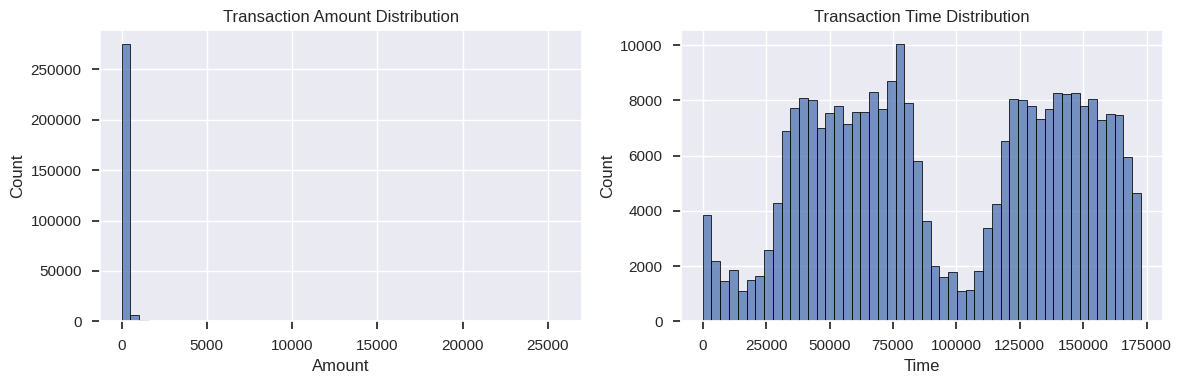

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(creditcard['Amount'], bins=50, ax=axes[0])
axes[0].set_title('Transaction Amount Distribution')

sns.histplot(creditcard['Time'], bins=50, ax=axes[1])
axes[1].set_title('Transaction Time Distribution')

plt.tight_layout()
plt.show()

The 'Amount' distribution is heavily right-skewed with most transactions involving small values.

The 'Time' feature shows a multi-modal distribution with several peaks. We can observe two similar peaks in the histogram which suggest daily transaction cycles, likely reflecting consumer behavior patterns. It matches the dataset's two-day time period.

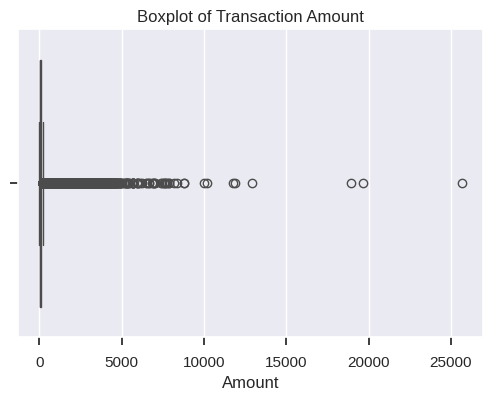

In [41]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=creditcard['Amount'])
plt.title('Boxplot of Transaction Amount')
plt.show()

We can see the same pattern of distribution here as well: It is highly right-skewed with the majority of transactions concentrated at low values. Because of this extreme skewness, the raw 'Amount' feature is unsuitable for direct modeling and requires transformation and scaling.

#### PCA features

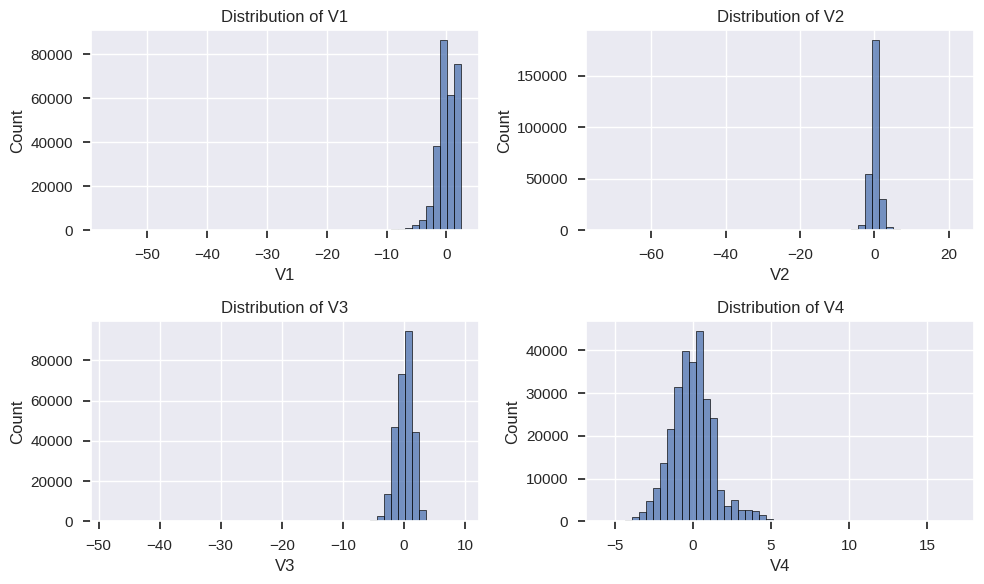

In [42]:
# a subset of PCA features (V1-V4)
pca_features = [f'V{i}' for i in range(1, 5)]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for i, col in enumerate(pca_features):
    sns.histplot(creditcard[col], bins=50, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

Several PCA components show skewness and heavy tails. While PCA ensures centering and decorrelation, it does not enforce normality. Downstream models and preprocessing steps should account for this behavior.

### PaySim Dataset

In [43]:
num_cols = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

#### 'amount' Distribution

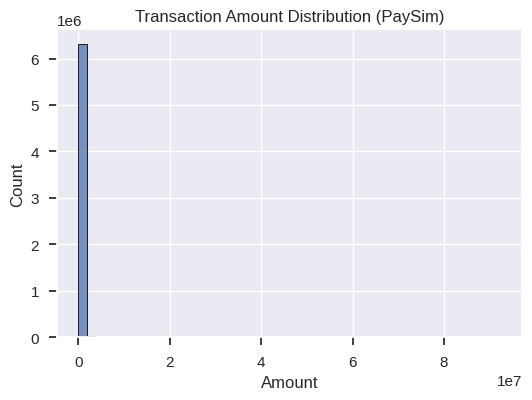

In [44]:
plt.figure(figsize=(6, 4))
sns.histplot(paysim['amount'], bins=50)
plt.title('Transaction Amount Distribution (PaySim)')
plt.xlabel('Amount')
plt.ylabel('Count')
plt.show()

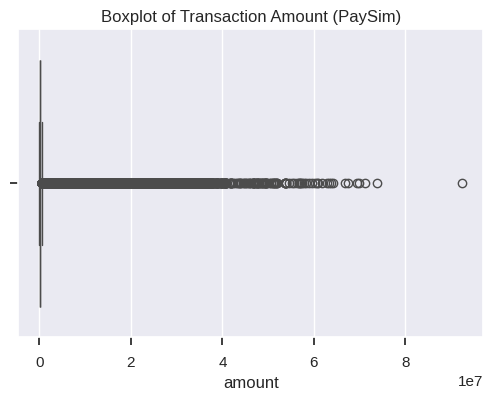

In [45]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=paysim['amount'])
plt.title('Boxplot of Transaction Amount (PaySim)')
plt.show()

The plots show that the `amount` feature distribution is heavily right skewed and has many near-zero values. This calls for log transformation and scaling alone wouldn't suffice.

#### Origin Account Balances

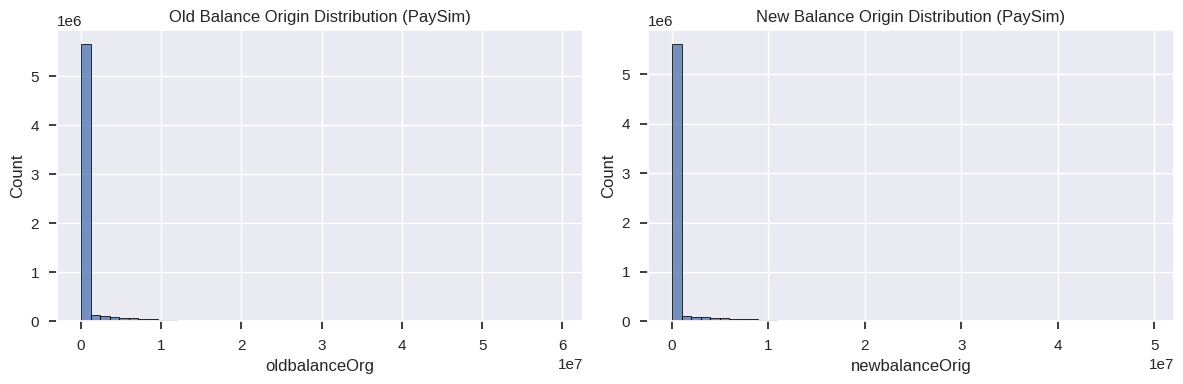

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(paysim['oldbalanceOrg'], bins=50, ax=axes[0])
axes[0].set_title('Old Balance Origin Distribution (PaySim)')

sns.histplot(paysim['newbalanceOrig'], bins=50, ax=axes[1])
axes[1].set_title('New Balance Origin Distribution (PaySim)')

plt.tight_layout()
plt.show()

#### Destination Account Balances

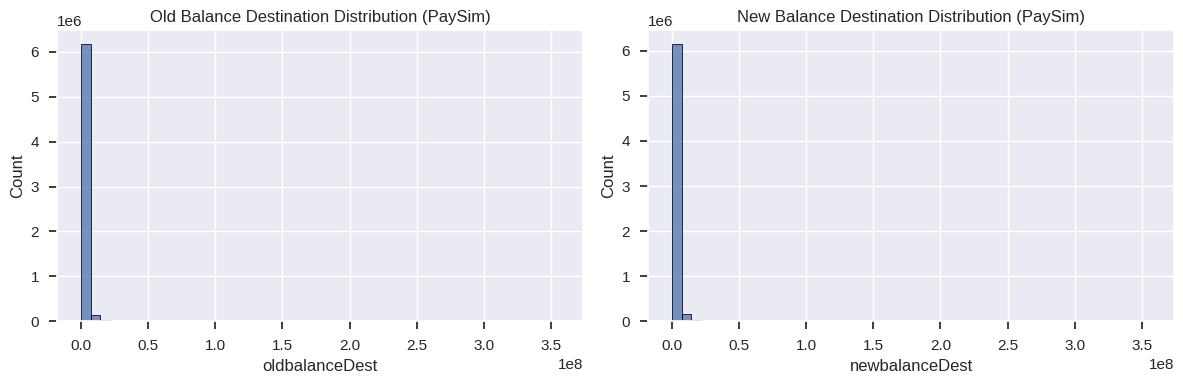

In [47]:
fig, axis = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(x=paysim['oldbalanceDest'], bins=50, ax=axis[0])
axis[0].set_title('Old Balance Destination Distribution (PaySim)')

sns.histplot(x=paysim['newbalanceDest'], bins=50, ax=axis[1])
axis[1].set_title('New Balance Destination Distribution (PaySim)')

plt.tight_layout()
plt.show()

The origin and destination balance features exhibit extreme right-skewness, with a large concentration of transactions occuring at or near zero balances and a long tail of high-value accounts.

These balance columns are affected by fraud cancellation logic. So they are not trustworthy for fraud prediction as it was described when loading the dataset in previous cells.

#### Transaction Type

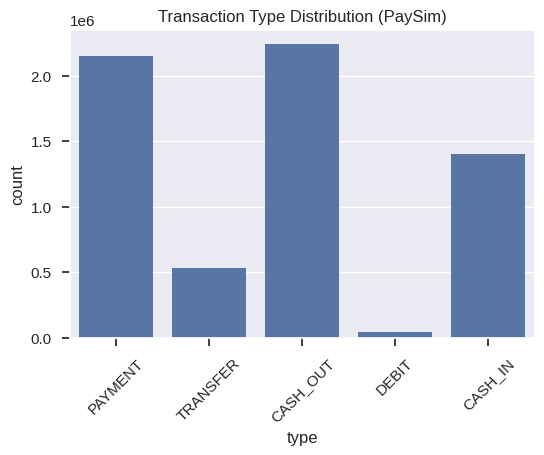

In [48]:
plt.figure(figsize=(6, 4))
sns.countplot(x='type',  data=paysim)
plt.title('Transaction Type Distribution (PaySim)')
plt.xticks(rotation=45)
plt.show()

We can clearly observe that the transaction type distribution in PaySim is highly imbalanced, with CASH_OUT and PAYMENT accounting for the majority of transactions, while TRANSFER and DEBIT occur much less frequently.

'type' feature is not a neutral categorical feature. Because fraud probability is conditional on type and we have strong prior information about the usual fraud transaction types which is mostly 'TRANSFER' and 'CASH_OUT'.

Since PaySim is synthetic, rule-driven dataset, transaction type encodes prior assumptions about fraud mechanisms. We need to be cautious as we may not be able to do direct generalization to real-word data unless we do careful evaluation.

## Fraud vs Non-Fraud Feature Comparison

Due to the extreme class imbalance present in both datasets, direct fraud vs non-fraud feature comparison on the full datasets are not informative, as fraud cases make up a very small fraction of the data.

To analyze fraud vs non-fraud feature behavior, two separate balanced comparison subsets are constructed for each dataset, used solely for exploratory analysis.
These subsets contain 1000 and 492 fraud transactions for PaySim and credit card dataset respectively and an equal number of randomly sampled non-fraud transactions.

These datasets are used only for EDA and not for model training or evaluation.

### Credit Card Dataset

In [ ]:
creditcard_balanced = pd.read_csv("../data/eda/creditcard_balanced_eda.csv")

creditcard_balanced.shape

(984, 31)

In [ ]:
creditcard_balanced['Class'].value_counts()

Class
0    492
1    492
Name: count, dtype: int64

In [ ]:
creditcard_balanced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    984 non-null    float64
 1   V1      984 non-null    float64
 2   V2      984 non-null    float64
 3   V3      984 non-null    float64
 4   V4      984 non-null    float64
 5   V5      984 non-null    float64
 6   V6      984 non-null    float64
 7   V7      984 non-null    float64
 8   V8      984 non-null    float64
 9   V9      984 non-null    float64
 10  V10     984 non-null    float64
 11  V11     984 non-null    float64
 12  V12     984 non-null    float64
 13  V13     984 non-null    float64
 14  V14     984 non-null    float64
 15  V15     984 non-null    float64
 16  V16     984 non-null    float64
 17  V17     984 non-null    float64
 18  V18     984 non-null    float64
 19  V19     984 non-null    float64
 20  V20     984 non-null    float64
 21  V21     984 non-null    float64
 22  V2

In [ ]:
target_col = 'Class'

num_cols = ['Time', 'Amount']

pca_features = creditcard_balanced.select_dtypes(include='float64').drop(columns=num_cols)

#### Amount Feature

In [ ]:
creditcard_balanced['log_amount'] = np.log1p(creditcard_balanced['Amount'])

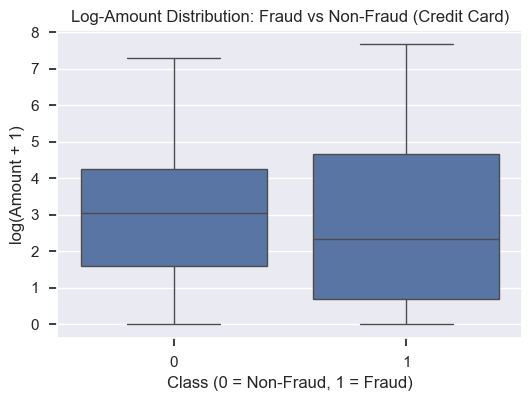

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=creditcard_balanced,
    x='Class',
    y='log_amount'
)
plt.title('Log-Amount Distribution: Fraud vs Non-Fraud (Credit Card)')
plt.xlabel('Class (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(Amount + 1)')
plt.show()

The log-transformed transaction amount shows substantial overlap between fraudulent and non-fraudulent transactions. Fraud cases exhibit a lower median amount but a wider spread, indicating that while fraudulent transactions are typically smaller, they span a broad range of values. Non-fraud transactions are more concentrated around moderate amounts. This pattern suggests that transaction amount alone provides limited discriminative power and is more informative when combined with other features.

#### Time Feature

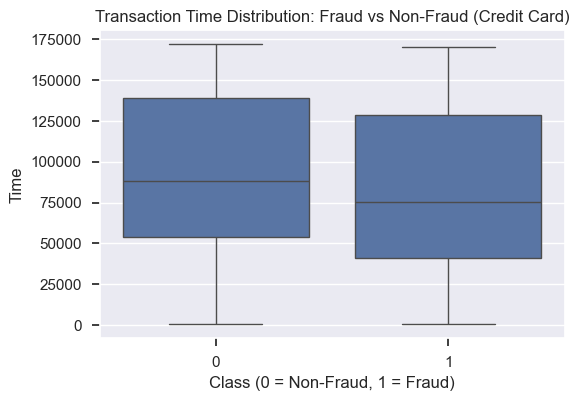

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=creditcard_balanced,
    x='Class',
    y='Time'
)
plt.title('Transaction Time Distribution: Fraud vs Non-Fraud (Credit Card)')
plt.xlabel('Class (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Time')
plt.show()

The distribution of the Time feature is highly similar for fraudulent and non-fraudulent transactions, with only a marginal difference in median values and substantial overlap across the entire range. Both classes exhibit comparable spread and variability, indicating no strong temporal separation. Since Time represents the elapsed seconds since the first recorded transaction rather than real-world clock time, it primarily serves as a contextual ordering variable rather than a meaningful predictor of fraud. Consequently, Time alone provides limited discriminative value and should be interpreted cautiously.

#### Summary

The fraud vs non-fraud analysis of the Credit Card dataset shows limited separability using the interpretable features available. Transaction amount exhibits substantial overlap between classes. Although fraudulent transactions have slightly lower median values and higher variability, amount alone is not a strong discriminator. The temporal feature (Time) displays nearly identical distributions across classes and primarily serves as an ordering variable rather than a behavioral indicator.

Since the remaining features are anonymized PCA components without semantic meaning, they were excluded from interpretive EDA. Overall, this real-world dataset does not show clear fraud patterns in interpretable feature space, highlighting the need for multivariate, model-based approaches.

### PaySim Dataset

In [ ]:
paysim_balanced = pd.read_csv(
    "../data/eda/paysim_balanced_eda.csv"
)

paysim_balanced.shape

(2000, 11)

In [ ]:
paysim_balanced["isFraud"].value_counts()

isFraud
0    1000
1    1000
Name: count, dtype: int64

In [ ]:
paysim_balanced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            2000 non-null   int64  
 1   type            2000 non-null   object 
 2   amount          2000 non-null   float64
 3   nameOrig        2000 non-null   object 
 4   oldbalanceOrg   2000 non-null   float64
 5   newbalanceOrig  2000 non-null   float64
 6   nameDest        2000 non-null   object 
 7   oldbalanceDest  2000 non-null   float64
 8   newbalanceDest  2000 non-null   float64
 9   isFraud         2000 non-null   int64  
 10  isFlaggedFraud  2000 non-null   int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 172.0+ KB


In [ ]:
paysim_balanced['isFraud'].unique()

array([0, 1])

In [ ]:
target_col = 'isFraud'
id_columns = ['nameOrig', 'nameDest']

categorical_features = [
    'type',
]

numerical_features = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'isFlaggedFraud'
]

categorical_features, numerical_features

(['type'],
 ['step',
  'amount',
  'oldbalanceOrg',
  'newbalanceOrig',
  'oldbalanceDest',
  'newbalanceDest',
  'isFlaggedFraud'])

In [ ]:
paysim_balanced.groupby('isFraud')[numerical_features].describe().T

isFraud                          0             1
step           count  1.000000e+03  1.000000e+03
               mean   2.431340e+02  3.667860e+02
               std    1.414151e+02  2.162874e+02
               min    8.000000e+00  2.000000e+00
               25%    1.540000e+02  1.787500e+02
               50%    2.360000e+02  3.655000e+02
               75%    3.310000e+02  5.522500e+02
               max    6.920000e+02  7.430000e+02
amount         count  1.000000e+03  1.000000e+03
               mean   1.618283e+05  1.500081e+06
               std    4.568853e+05  2.367939e+06
               min    4.900000e+00  0.000000e+00
               25%    1.344104e+04  1.438683e+05
               50%    7.869196e+04  4.876534e+05
               75%    2.092616e+05  1.582579e+06
               max    1.199796e+07  1.000000e+07
oldbalanceOrg  count  1.000000e+03  1.000000e+03
               mean   7.874901e+05  1.657553e+06
               std    2.609007e+06  3.277769e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  1.433381e+05
               50%    1.235850e+04  4.867261e+05
               75%    1.005645e+05  1.582579e+06
               max    2.598035e+07  3.567455e+07
newbalanceOrig count  1.000000e+03  1.000000e+03
               mean   8.120422e+05  1.713835e+05
               std    2.655532e+06  1.655264e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    0.000000e+00  0.000000e+00
               75%    1.392484e+05  0.000000e+00
               max    2.624326e+07  2.567455e+07
oldbalanceDest count  1.000000e+03  1.000000e+03
               mean   1.017214e+06  4.558999e+05
               std    2.296820e+06  2.014433e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    1.349609e+05  0.000000e+00
               75%    8.760205e+05  1.328585e+05
               max    2.815628e+07  4.614176e+07
newbalanceDest count  1.000000e+03  1.000000e+03
               mean   1.117619e+06  1.197247e+06
               std    2.455159e+06  2.805461e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    2.170352e+05  9.086310e+03
               75%    1.048544e+06  1.083004e+06
               max    2.805790e+07  4.690801e+07
isFlaggedFraud count  1.000000e+03  1.000000e+03
               mean   0.000000e+00  2.000000e-03
               std    0.000000e+00  4.469897e-02
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    0.000000e+00  0.000000e+00
               75%    0.000000e+00  0.000000e+00
               max    0.000000e+00  1.000000e+00

Fraud transactions
- are more frequent in later time steps, suggesting temporal drift or delayed exploitation behavior in the simulated system.

- are associated with substantially higher transaction amounts, indicating that amount is a strong discriminative feature.

- frequently drain the origin account to zero, indicating full balance extraction behavior.

- often transfer funds into previously inactive or empty destination accounts, consistent with mule-account behavior.

The system flagging mechanism fails to detect the vast majority of fraudulent transactions, highlighting weak rule-based detection process.

#### Amount feature

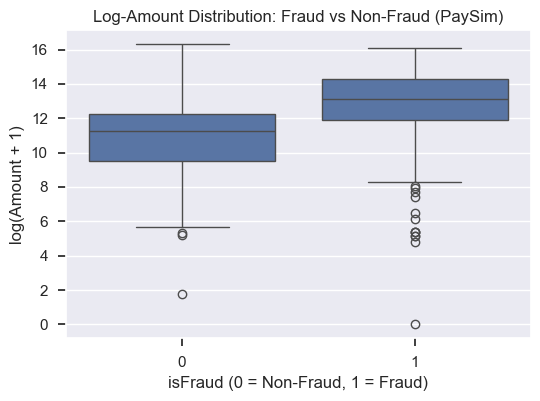

In [ ]:
paysim_balanced['log_amount'] = np.log1p(paysim_balanced['amount'])

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_amount'
)
plt.title('Log-Amount Distribution: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(Amount + 1)')
plt.show()

The log-transformed transaction amount shows a clear shift between fraud and non-fraud transactions. Fraudulent transactions tend to have higher median amounts and a wider spread, indicating greater variability in fraud-related transaction sizes. However, the substantial overlap between the two distributions suggests that transaction amount alone does not clearly separate fraud from non-fraud and should be interpreted in combination with other features.

#### oldbalanceOrg

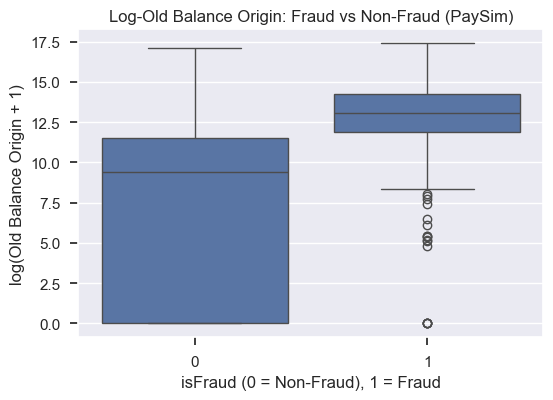

In [ ]:
paysim_balanced['log_oldbalanceOrg'] = np.log1p(paysim_balanced['oldbalanceOrg'])

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_oldbalanceOrg'
)
plt.title('Log-Old Balance Origin: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud), 1 = Fraud')
plt.ylabel('log(Old Balance Origin + 1)')
plt.show()

The log-transformed origin balance exhibits a clear difference between fraud and non-fraud transactions. Fraudulent transactions generally have a higher median origin balance and a more concentrated spread compared to non-fraud cases. At the same time, a noticeable number of fraud transactions occur at zero or near-zero origin balances, as reflected by the lower-end outliers.

This pattern likely reflects the synthetic and rule-based nature of the PaySim dataset, where some fraudulent transactions are aborted or do not update balances consistently. Therefore, while origin balance exhibits discriminative behavior, it should be treated with caution due to potential artifacts.

#### newbalanceOrg

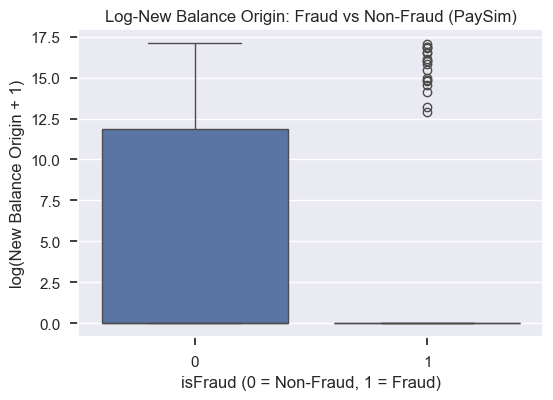

In [ ]:
paysim_balanced['log_newbalanceOrig'] = np.log1p(paysim_balanced['newbalanceOrig'])

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_newbalanceOrig'
)

plt.title('Log-New Balance Origin: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(New Balance Origin + 1)')
plt.show()

The log-transformed new origin balance shows a different pattern for fraud and non-fraud transactions. Fraudulent transactions have a median close to zero, with many values clustered at zero. This suggests that, in many fraud cases, the origin account is almost completely emptied after the simulated transaction. Non-fraud transactions, on the other hand, show a much wider spread, indicating a broad range of remaining balances. Although a small number of fraud cases also have high post-transaction balances, these appear only as rare outliers. Overall, the strong concentration observed in fraud cases seems to be driven more by the synthetic, rule-based nature of the PaySim dataset than by natural variation in real financial behavior.

Looking at the outliers in fraud boxplot, fraud labels can appear alongside balance values that do not reflect completed financial transfers. This reinforces the need to interpret post-transaction balance features with caution.

#### oldbalanceDest

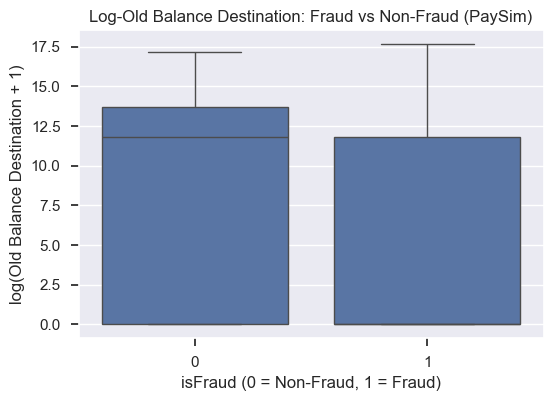

In [ ]:
paysim_balanced['log_oldbalanceDest'] = np.log1p(paysim_balanced['oldbalanceDest'])

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_oldbalanceDest'
)
plt.title('Log-Old Balance Destination: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(Old Balance Destination + 1)')
plt.show()

The log-transformed destination balance before the transaction shows very similar patterns for fraud and non-fraud cases. Both groups have high median values and a wide spread, which suggests that destination accounts often contain large balances regardless of whether a transaction is fraudulent. Although the median balance is slightly higher for non-fraud transactions, the interquartile ranges overlap heavily, indicating little separation between the two groups. Overall, this distribution suggests that the destination’s initial balance alone does not strongly distinguish between fraudulent and legitimate transactions and should be interpreted in the context of PaySim’s synthetic, rule-based transaction structure.

#### newbalanceDest

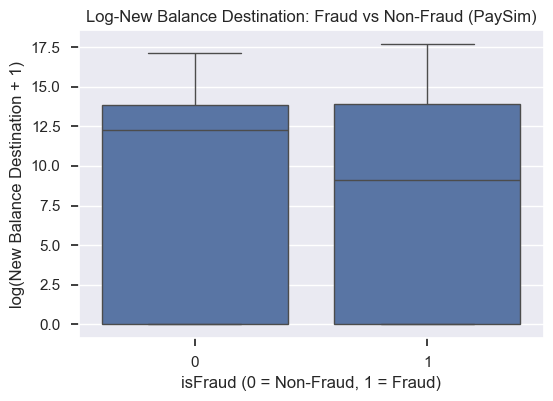

In [ ]:
paysim_balanced['log_newbalanceDest'] = np.log1p(paysim_balanced['newbalanceDest'])

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_newbalanceDest'
)
plt.title('Log-New Balance Destination: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(New Balance Destination + 1)')
plt.show()

The log-transformed destination balance after the transaction shows largely similar distribution patterns for fraudulent and non-fraudulent transactions. Both groups have high median values and wide IQR, indicating that destination accounts often retain substantial balances after receiving funds. Although the median balance for fraudulent transactions is slightly lower than that for non-fraud cases, the difference is small. There is significant overlap between the two distributions, suggesting that post-transaction destination balances alone do not provide a clear distinction between fraudulent and legitimate activity. The lack of strong outliers in either group further indicates that high destination balances are common and consistently generated within the PaySim simulation. Overall, this feature has limited discriminative value on its own and should be analyzed alongside other transaction-related variables.

#### Origin Balance Delta

In [ ]:
paysim_balanced['delta_balanceOrig'] = (
    paysim_balanced['oldbalanceOrg'] - paysim_balanced['newbalanceOrig']
)

In [ ]:
paysim_balanced['log_delta_balanceOrig'] = np.log1p(
    paysim_balanced['delta_balanceOrig'].clip(lower=0)
)

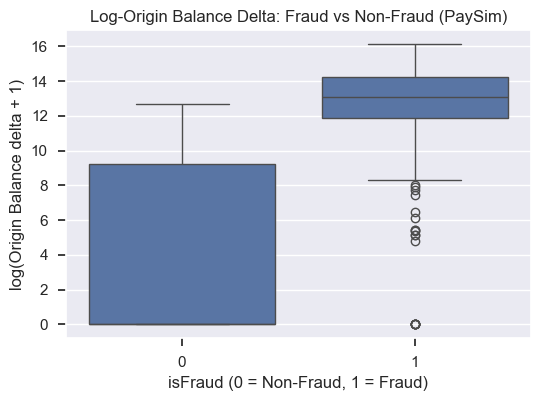

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_delta_balanceOrig'
)

plt.title('Log-Origin Balance Delta: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(Origin Balance delta + 1)')
plt.show()

The log-transformed change in the origin account balance shows a clear difference between fraudulent and non-fraudulent transactions. Fraud cases have a much higher median and a more tightly grouped distribution, indicating that fraudulent transactions usually involve large reductions in the origin balance. In contrast, non-fraud transactions display a wider spread, with many values close to zero, which reflects smaller or partial balance changes. Although most fraud cases show large balance differences, a small number of low-value outliers suggest that not all fraudulent transactions lead to complete balance updates. This pattern aligns with PaySim’s documented behavior, where some fraud attempts may be interrupted or applied inconsistently, resulting in mismatches between transaction labels and balance changes. Therefore, while the origin balance delta shows strong separation between the two classes, it should be interpreted carefully, as it may partly reflect simulation-specific artifacts and could introduce information leakage if used without proper context.

#### Destination Balance Delta

In [ ]:
paysim_balanced['delta_balanceDest'] = (
    paysim_balanced['oldbalanceDest'] - paysim_balanced['newbalanceDest']
)

In [ ]:
paysim_balanced['log_delta_balanceDest'] = np.log1p(
    paysim_balanced['delta_balanceDest'].clip(lower=0)
)

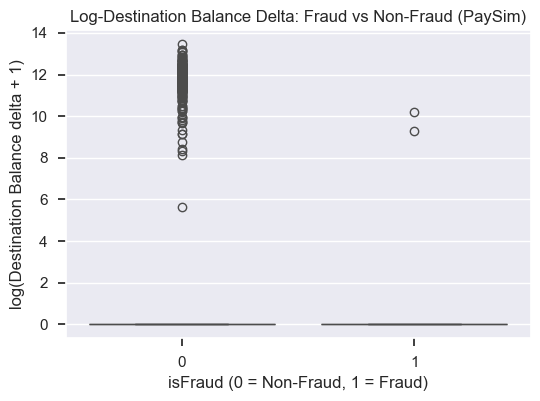

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='log_delta_balanceDest'
)

plt.title('Log-Destination Balance Delta: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('log(Destination Balance delta + 1)')
plt.show()

The log-transformed change in the destination account balance shows a strong clustering at zero for both fraudulent and non-fraudulent transactions. This indicates that, in most cases, the destination balance does not decrease after a transaction, which is expected since destination accounts typically receive funds. A small subset of non-fraud transactions exhibits large positive deltas, visible as high outliers, reflecting atypical cases where destination balances decrease substantially. In contrast, fraudulent transactions contain very few non-zero values, and those observed are limited to a small number of moderate outliers. The heavy concentration at zero and the sparse, irregular outliers suggest that this feature is largely driven by PaySim’s rule-based simulation rather than natural financial behavior. Consequently, the destination balance delta provides limited standalone discriminative power and should be interpreted cautiously, particularly in light of PaySim’s known balance inconsistencies.

#### type feature

In [ ]:
paysim_balanced.groupby(['type', 'isFraud']).size().unstack()

isFraud,0,1
type,,
CASH_IN,207.0,NaN
CASH_OUT,371.0,510.0
DEBIT,5.0,NaN
PAYMENT,349.0,NaN
TRANSFER,68.0,490.0


In [ ]:
# proportion of fraud in each type
type_fraud_rate = (
    paysim_balanced
    .groupby('type')['isFraud']
    .mean()
    .sort_values(ascending=False)
)

type_fraud_rate

type
TRANSFER    0.878136
CASH_OUT    0.578888
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64

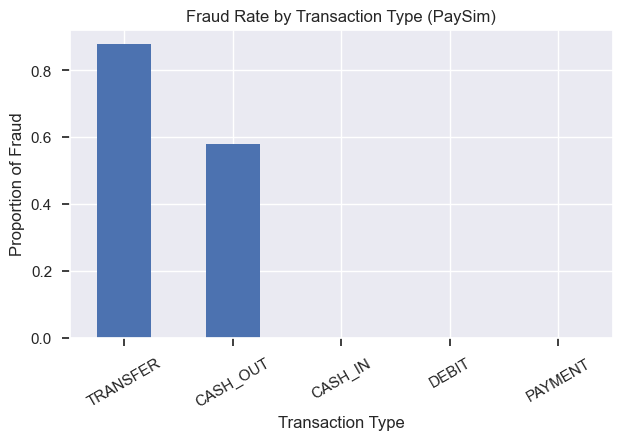

In [ ]:
plt.figure(figsize=(7, 4))
type_fraud_rate.plot(kind='bar')

plt.title('Fraud Rate by Transaction Type (PaySim)')
plt.xlabel('Transaction Type')
plt.ylabel('Proportion of Fraud')
plt.xticks(rotation=30)
plt.show()

The distribution of fraud across transaction types shows a strong relationship between transaction type and fraudulent activity. Fraud occurs almost entirely in TRANSFER and CASH_OUT transactions, while other types such as PAYMENT, DEBIT, and CASH_IN show no fraud. This clear separation reflects the rule-based design of the PaySim simulator, in which only certain transaction types are allowed to produce fraudulent behavior. As a result, transaction type becomes a highly predictive feature. However, because of its deterministic nature, it may strongly influence model learning and should be treated with caution to avoid overly optimistic performance estimates.

#### isFlaggedFraud feature

In [ ]:
pd.crosstab(
    paysim_balanced['isFlaggedFraud'],
    paysim_balanced['isFraud']
)

isFraud,0,1
isFlaggedFraud,,
0,1000,998
1,0,2


The relationship between isFlaggedFraud and isFraud reveals that this feature is extremely sparse and rule-driven. Only a very small number of transactions are flagged, and all flagged cases correspond to fraud, indicating perfect precision but negligible recall. The vast majority of fraudulent transactions are not flagged by this indicator. This behavior reflects the deterministic design of the PaySim simulator rather than a realistic fraud detection process. As a result, while isFlaggedFraud is strongly associated with fraud labels, it primarily encodes simulator logic and may introduce information leakage if used for predictive modeling. Therefore, it should be interpreted with caution and excluded from downstream models.

#### step feature

In [ ]:
paysim_balanced.groupby('isFraud')['step'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,1000.0,243.134,141.415057,8.0,154.00,236.0,331.00,692.0
1,1000.0,366.786,216.287402,2.0,178.75,365.5,552.25,743.0


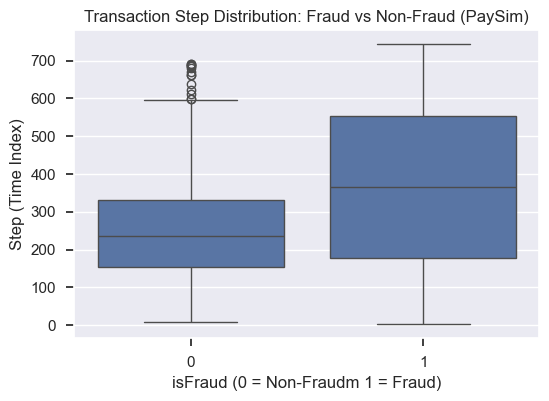

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=paysim_balanced,
    x='isFraud',
    y='step'
)
plt.title('Transaction Step Distribution: Fraud vs Non-Fraud (PaySim)')
plt.xlabel('isFraud (0 = Non-Fraudm 1 = Fraud)')
plt.ylabel('Step (Time Index)')
plt.show()

The distribution of the step feature suggests that fraudulent transactions tend to occur later in the simulation compared to non-fraud cases. Fraudulent transactions show a higher median step value and a wider interquartile range, indicating greater spread over time. However, there is still considerable overlap between the two distributions, meaning that fraud is not limited only to the final stages of the simulation. This temporal shift appears to be driven by the internal dynamics of the PaySim simulator rather than by a natural timing pattern of fraudulent behavior. As a result, the step feature should be viewed primarily as a contextual indicator of simulation progress and interpreted with caution when considering its relevance beyond the synthetic PaySim environment.

#### Summary

Fraudulent and non-fraudulent transactions in the PaySim dataset show consistent differences across several key features. Fraud is heavily concentrated in specific transaction types, especially `TRANSFER` and `CASH_OUT`, while other transaction types contain very few or no fraudulent cases. This pattern indicates that fraudulent behavior in the simulation is closely linked to transaction type and context.

Fraudulent transactions also tend to involve **larger transaction amounts** and display distinctive patterns in balance-related features. In fraud cases, **origin account balances** often decrease sharply, while **destination balance changes** can appear irregular, suggesting unusual fund movements. The log-transformed balance features show some overlap between fraud and non-fraud cases, but with noticeable shifts in their central values.

The temporal feature `step` indicates that fraudulent transactions generally occur later in the simulation, with a higher median and a wider spread compared to non-fraud cases. However, the overlap between the two groups remains substantial, meaning that step mainly reflects the progression of the simulation rather than serving as a strong independent predictor of fraud. Finally, the `isFlaggedFraud` feature is extremely rare and captures only a very small portion of fraudulent transactions, highlighting the limited effectiveness of PaySim’s built-in, rule-based fraud detection.

### PaySim vs Credit Card Fraud Datasets

The PaySim and Credit Card datasets exhibit fundamentally different fraud characteristics that influence how they should be analyzed and modeled. PaySim, as a synthetic dataset, shows strong and interpretable fraud patterns that are closely tied to transaction type and amount, making fraudulent behavior relatively easy to distinguish through exploratory analysis. In contrast, the Credit Card dataset reflects real-world complexity: features are anonymized via PCA, class separation is subtle, and individual variables show limited discriminative power. As a result, while PaySim supports rule-based insights and intuitive feature interpretation, the Credit Card dataset requires deeper statistical analysis and model-driven approaches to uncover fraud-related structure. These differences highlight the importance of adapting both EDA focus and modeling strategy to the nature of each dataset rather than applying a uniform analytical approach.

## Feature Correlation Analysis

### Credit Card Dataset

In [50]:
creditcard.isnull().sum().sum()

np.int64(0)

In [51]:
corr_matrix = creditcard.corr()

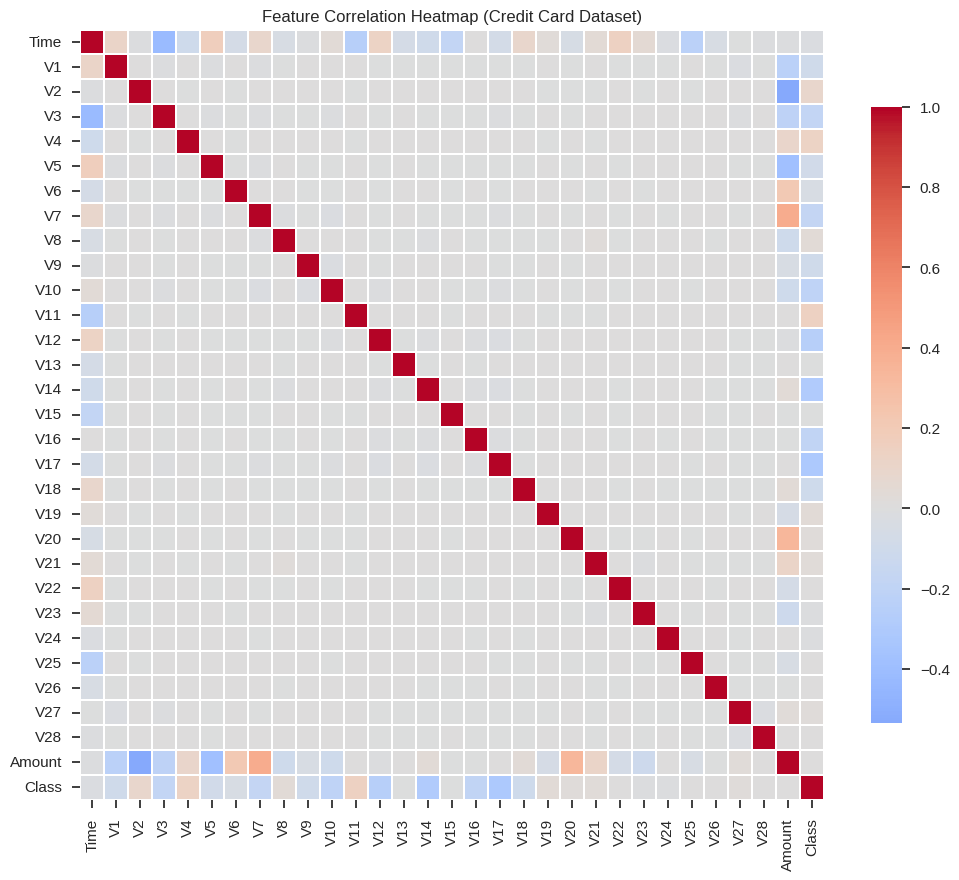

In [52]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink":0.8}
)
plt.title("Feature Correlation Heatmap (Credit Card Dataset)")
plt.show()

Global Feature Correlation

The correlation heatmap indicates low overall multicollinearity in the Credit Card dataset, which is expected given its PCA-based feature construction. Most features exhibit weak pairwise correlations, suggesting that the anonymized components are largely independent. This suggests that correlation-based feature pruning is unlikely to be beneficial in this context.

No feature demonstrates a strong linear correlation with the fraud label. Instead, fraud-related information appears to be distributed across multiple features through relatively weak individual relationships. The Amount and Time features show near-zero correlation with both other features and the target, indicating limited standalone predictive value in a linear context.

In [54]:
class_corr = (
    corr_matrix['Class']
    .drop('Class')
    .sort_values(key=abs, ascending=False)
)

class_corr.head(10)

,Class
V17,-0.313498
V14,-0.293375
V12,-0.250711
V10,-0.206971
V16,-0.187186
V3,-0.182322
V7,-0.172347
V11,0.149067
V4,0.129326
V18,-0.105340


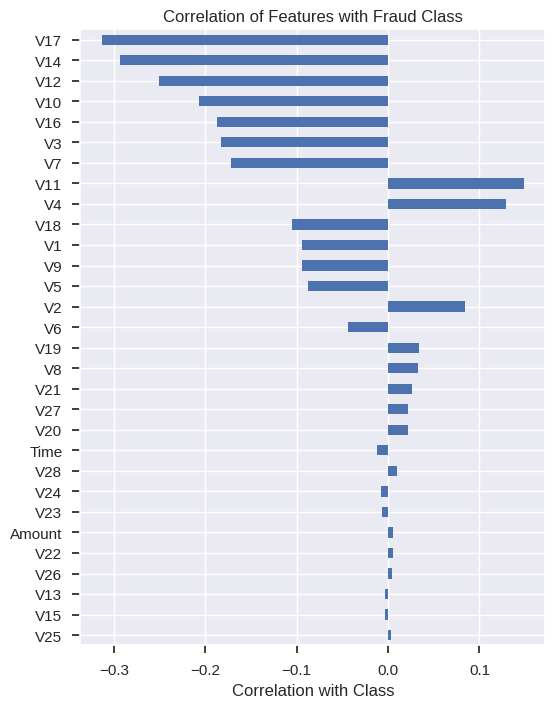

In [55]:
plt.figure(figsize=(6, 8))
class_corr.plot(kind='barh')
plt.title('Correlation of Features with Fraud Class')
plt.xlabel("Correlation with Class")
plt.gca().invert_yaxis()
plt.show()

Correlation with Fraud Class

The correlation analysis with the fraud label confirms that no single feature dominates fraud detection in this dataset. Several anonymized components (such as V17, V14, V12, V10, and V11) show moderate positive or negative correlations with the target, suggesting they capture underlying transaction patterns associated with fraudulent behavior. However, none of these features alone provides sufficient discriminative power.

Overall, these results highlight that fraud detection in the Credit Card dataset is driven by subtle patterns spread across many features rather than by strong linear signals from a small number of variables.

### PaySim Dataset

In [57]:
num_cols = paysim[[
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'isFraud',
    'isFlaggedFraud'
]]

corr_matrix_paysim = num_cols.corr()

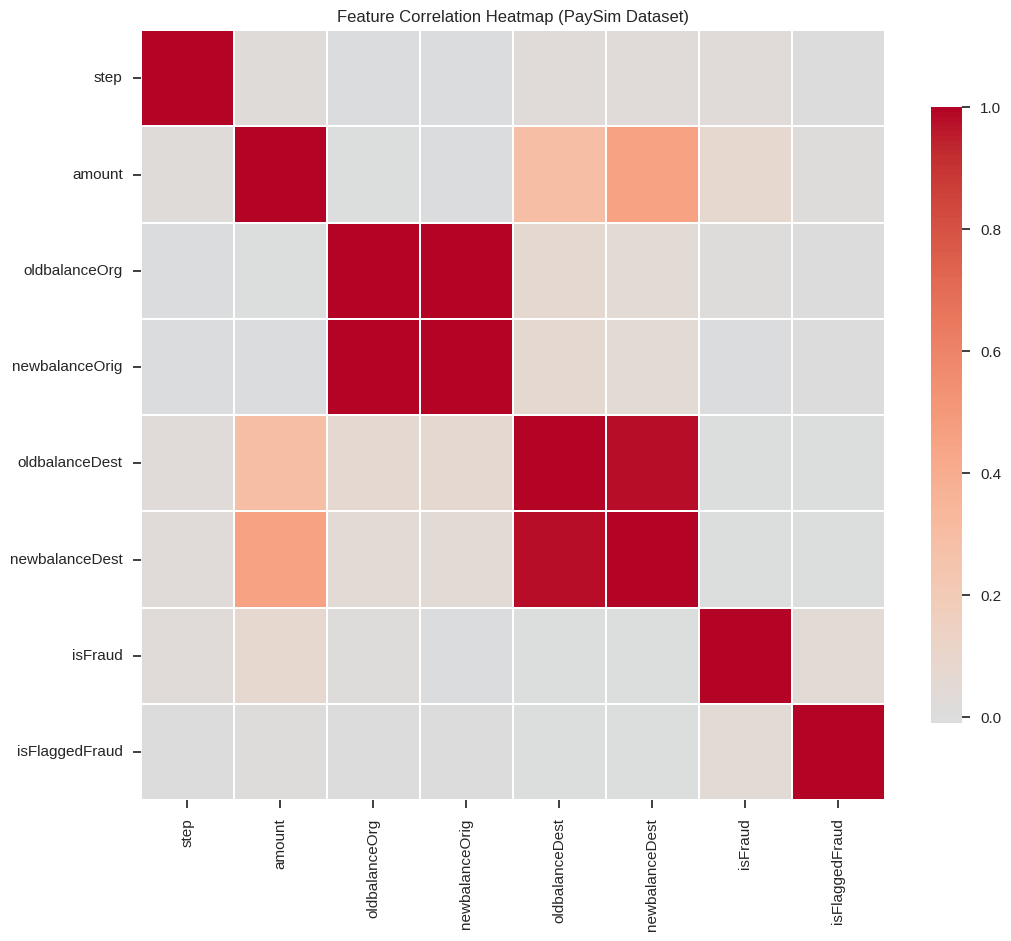

In [59]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix_paysim,
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8}
)
plt.title("Feature Correlation Heatmap (PaySim Dataset)")
plt.show()

In [60]:
import numpy as np

threshold = 0.9

upper = corr_matrix_paysim.where(
    np.triu(np.ones(corr_matrix_paysim.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={0: "correlation"})
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"].abs() >= threshold
]

high_corr_pairs.sort_values(
    by="correlation",
    key=lambda x: x.abs(),
    ascending=False
)


,level_0,level_1,correlation
13,oldbalanceOrg,newbalanceOrig,0.998803
22,oldbalanceDest,newbalanceDest,0.976569


The strongest correlations in the PaySim dataset are observed between oldbalanceOrg and newbalanceOrig, as well as between oldbalanceDest and newbalanceDest. These near-perfect correlations arise from the deterministic balance update rules used in the simulation, rather than from meaningful behavioral patterns.

Such relationships are expected in transaction-level accounting data and indicate the presence of mechanically linked features. As a result, these features should be handled carefully in later modeling stages to avoid misleading conclusions.

In [61]:
class_corr_paysim = (
    corr_matrix_paysim['isFraud']
    .drop('isFraud')
    .sort_values(key=abs, ascending=False)
)

class_corr_paysim

,isFraud
amount,0.076688
isFlaggedFraud,0.044109
step,0.031578
oldbalanceOrg,0.010154
newbalanceOrig,-0.008148
oldbalanceDest,-0.005885
newbalanceDest,0.000535


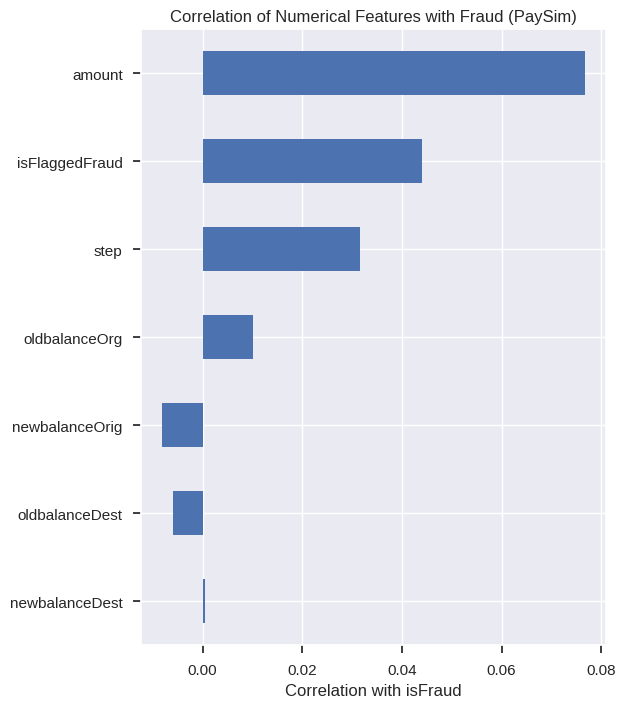

In [62]:
plt.figure(figsize=(6, 8))
class_corr_paysim.sort_values(key=abs).plot(kind='barh')
plt.title('Correlation of Numerical Features with Fraud (PaySim)')
plt.xlabel('Correlation with isFraud')
plt.show()

The correlation analysis between numerical features and the fraud label (isFraud) shows no strong linear relationships. Transaction amount has the highest correlation with fraud, but the value is still weak, indicating considerable overlap between fraudulent and non-fraudulent transactions. Other features, such as account balances and the simulation step, have correlations close to zero, suggesting that they have limited predictive value when considered on their own in a linear context.

The isFlaggedFraud variable shows a small positive correlation with the target, which reflects its rule-based definition within the simulator rather than a true behavioral pattern. Overall, fraud in the PaySim dataset does not appear to be explained by any single numerical feature, highlighting the need for multivariate and non-linear modeling approaches.

#### Cross-Dataset Correlation Comparison


Both datasets show no strong linear correlation between individual features and the fraud label. In each case, fraud-related information is spread across multiple variables, indicating that simple rule-based detection using a single feature is not effective. This supports the use of multivariate and non-linear modeling approaches for both datasets.

Despite this similarity, their correlation structures differ clearly. The Credit Card dataset shows very low multicollinearity, which is expected due to its PCA-based feature design and reflects a more realistic data-generating process. In contrast, the PaySim dataset contains strong correlations among balance-related features, caused by deterministic accounting rules in the simulation. Although these correlations do not directly involve the fraud label, they introduce structural dependencies that require careful handling during modeling.

Overall, while both datasets lack dominant linear fraud predictors, the Credit Card dataset reflects naturally distributed signals, whereas PaySim includes simulation-driven patterns and rule-based elements. These differences justify dataset-specific modeling choices, even though both benefit from non-linear learning methods.